# 🚲 Os quatro entregadores do bairro: Value Iteration, Policy Iteration, Monte Carlo e TD

Este notebook acompanha os **slides 76 a 85** da aula ("Como o agente aprende").

**A pergunta-chave (slide 77):** o agente **conhece as regras do mundo**, isto é, quem paga o quê e para onde cada ação leva?

| | Personagem | Método | Conhece o mapa? | Como aprende |
|---|---|---|---|---|
| 🗺️ | **O Cartógrafo** | Value Iteration | ✅ sim | Calcula no papel o valor de cada esquina antes de dar um passo |
| 🔧 | **O Treinador** | Policy Iteration | ✅ sim | Testa a estratégia, corrige o ponto fraco e testa de novo |
| 🍽️ | **O Crítico** | Monte Carlo | ❌ não | Só dá a nota depois de terminar a entrega inteira |
| 🚗 | **O Motorista** | Diferença Temporal | ❌ não | Corrige a previsão a cada esquina |

**O cenário de todos eles:** um bairro com ruas, quarteirões cheios de casas, um **Cliente** esperando a entrega e um **cachorro bravo** solto numa esquina. É o mesmo bairro para os quatro, para que dê para comparar.

- 🏭 **Depósito:** de onde o entregador sai.
- 🏁 **Cliente:** +1 de gorjeta, e a entrega termina.
- 🐕 **Cão bravo:** −1 (uma mordida), e a entrega termina.
- 🏠 **Quarteirões:** cheios de casas; a bicicleta não atravessa.
- ⏱️ **γ = 0,9:** a gorjeta encolhe 10% a cada quadra de atraso.

### Roteiro (≈ 35 min)

| Seção | Personagem | Slides | Tempo |
|---|---|---|---|
| 0 | O bairro em código | — | 3 min |
| 1 | 🗺️ O Cartógrafo: o boato se espalha pelo bairro | 78–79 | 7 min |
| 2 | 🔧 O Treinador: consertando a regra do chefe | 80 | 5 min |
| 3 | 🍽️ O Crítico: nota só no fim da entrega | 81 | 5 min |
| 4 | 🚗 O Motorista: a volta para casa (**item 1 do slide 85**) | 83–84 | 5 min |
| 5 | Crítico × Motorista lado a lado (**item 2 do slide 85**) | 82 | 5 min |
| 6 | A corrida (**item 3 do slide 85**) | 85 | 5 min |

> **Como usar:** rode as células em ordem (Shift + Enter). Sempre que aparecer **🤔 Palpite**, a dupla escreve a aposta **antes** de rodar. Onde aparecer 👈, troque o valor e rode de novo.

### 🎯 Aquecimento: quem é quem?

Associe cada situação a um dos quatro personagens:

1. O Waze recalculando a hora de chegada a cada semáforo.
2. Um gerente que só avalia a campanha de marketing quando ela termina.
3. Um engenheiro que calcula a melhor rota no mapa antes de sair de casa.
4. Um técnico que testa um esquema tático, corrige o ponto fraco e testa de novo.

<details>
<summary><b>Ver respostas</b></summary>

1 → 🚗 Motorista (TD) · 2 → 🍽️ Crítico (Monte Carlo) · 3 → 🗺️ Cartógrafo (Value Iteration) · 4 → 🔧 Treinador (Policy Iteration)
</details>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon
from matplotlib import animation
from IPython.display import HTML


def br(x, d=2):
    '''Número no formato brasileiro (e sem o feio "-0,00").'''
    t = f'{x:.{d}f}'
    if float(t) == 0:
        t = f'{0:.{d}f}'
    return t.replace('.', ',')

---
## 0. O bairro em código

O bairro é desenhado com **texto**: cada símbolo é uma esquina (ou um pedaço de quarteirão).

| Símbolo | Significa |
|---|---|
| `.` | rua |
| `#` | quarteirão com casas (a bicicleta não entra) |
| `D` | Depósito (saída) |
| `C` | Cliente: **+1**, fim da entrega |
| `X` | Cão bravo: **−1**, fim da entrega |

- **Estados:** as esquinas de rua (cada `.` e o `D`).
- **Ações:** ↑ → ↓ ←. Se a bicicleta tentar entrar num quarteirão ou sair do bairro, **bate e fica onde está**.
- **Recompensa:** só ao chegar ao Cliente (+1) ou ao cão (−1). No resto, 0.

A função `passo` é o **modelo do mundo**, o "mapa". O Cartógrafo e o Treinador podem consultá-la à vontade. O Crítico e o Motorista **não**: eles só descobrem o bairro andando por ele.

In [2]:
MAPA = '''
. . . . . . . . . C
. # # . # # . # # .
. # # . # # . # # .
. . . . . . X . . .
. # # . # # . # # .
. # # . # # . # # .
D . . . . . . . . .
'''

ACOES = {'↑': (-1, 0), '→': (0, 1), '↓': (1, 0), '←': (0, -1)}
RECOMPENSA = {'C': +1.0, 'X': -1.0}


def usar_mapa(texto):
    '''Lê o desenho do bairro e prepara as variáveis globais do mundo.'''
    global GRADE, LIN, COL, ESTADOS, DEPOSITO
    GRADE = [linha.split() for linha in texto.strip().splitlines()]
    LIN, COL = len(GRADE), len(GRADE[0])
    ESTADOS = [(l, c) for l in range(LIN) for c in range(COL) if GRADE[l][c] in '.D']
    DEPOSITO = next(s for s in ESTADOS if GRADE[s[0]][s[1]] == 'D')


def passo(s, a):
    '''O MAPA: da esquina s, pedalar na direção a. Devolve (próxima esquina, recompensa, terminou).'''
    l, c = s[0] + ACOES[a][0], s[1] + ACOES[a][1]
    if not (0 <= l < LIN and 0 <= c < COL) or GRADE[l][c] == '#':
        l, c = s                                   # bateu no quarteirão: fica onde está
    tipo = GRADE[l][c]
    return (l, c), RECOMPENSA.get(tipo, 0.0), tipo in RECOMPENSA


def tabela_vazia():
    '''Uma tabela V com 0 nas ruas e "nada" (nan) nos quarteirões.'''
    V = np.zeros((LIN, COL))
    for l in range(LIN):
        for c in range(COL):
            if GRADE[l][c] == '#':
                V[l, c] = np.nan
    return V


usar_mapa(MAPA)
print(f'Bairro de {LIN} × {COL}: {len(ESTADOS)} esquinas de rua. Depósito em {DEPOSITO}.')

Bairro de 7 × 10: 44 esquinas de rua. Depósito em (6, 0).


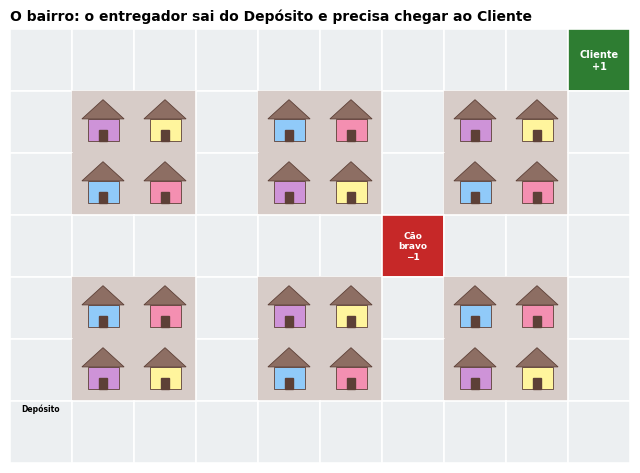

In [3]:
# @title 🎨 Função de desenho do bairro (pode só rodar)
CORES_CASA = ['#FFCC80', '#90CAF9', '#F48FB1', '#A5D6A7', '#CE93D8', '#FFF59D']


def desenhar_bairro(ax, V=None, politica=None, titulo='', destaque=(), rota=None, numeros=True, fonte=8):
    '''Desenha o bairro. V = valor de cada esquina (cor + número); politica = seta de cada esquina;
    destaque = esquinas com contorno rosa; rota = lista de esquinas ligadas por uma linha azul.'''
    ax.set_xlim(-.5, COL - .5); ax.set_ylim(LIN - .5, -.5); ax.set_aspect('equal'); ax.axis('off')
    for l in range(LIN):
        for c in range(COL):
            tipo, s = GRADE[l][c], (l, c)
            if tipo == '#':                                   # quarteirão com uma casinha
                ax.add_patch(Rectangle((c - .5, l - .5), 1, 1, color='#D7CCC8'))
                cor = CORES_CASA[(3 * l + c) % len(CORES_CASA)]
                ax.add_patch(Rectangle((c - .25, l - .05), .5, .36, facecolor=cor, edgecolor='#5D4037', lw=.6))
                ax.add_patch(Polygon([(c - .34, l - .05), (c, l - .36), (c + .34, l - .05)],
                                     facecolor='#8D6E63', edgecolor='#5D4037', lw=.6))
                ax.add_patch(Rectangle((c - .06, l + .13), .12, .18, color='#5D4037'))
                continue
            if tipo in RECOMPENSA:
                face = '#2E7D32' if tipo == 'C' else '#C62828'
            elif V is None:
                face = '#ECEFF1'
            else:
                face = plt.cm.RdYlGn(.5 + .5 * np.clip(V[l, c], -1, 1))
            marcado = s in destaque
            ax.add_patch(Rectangle((c - .5, l - .5), 1, 1, facecolor=face, zorder=2 if marcado else 1,
                                   edgecolor='#E91E63' if marcado else 'white', lw=3 if marcado else 1.2))
            if tipo == 'C':
                ax.text(c, l, 'Cliente\n+1', ha='center', va='center', fontsize=fonte - 1, color='white', fontweight='bold')
                continue
            if tipo == 'X':
                ax.text(c, l, 'Cão\nbravo\n−1', ha='center', va='center', fontsize=fonte - 1.5, color='white', fontweight='bold')
                continue
            if tipo == 'D':
                ax.text(c, l - .38, 'Depósito', ha='center', va='center', fontsize=fonte - 2.5, fontweight='bold')
            com_numero = V is not None and numeros
            if com_numero:
                ax.text(c, l - .1 if politica else l + .04, br(V[l, c]), ha='center', va='center', fontsize=fonte, zorder=3)
            if politica and s in politica:
                ax.text(c, l + .24 if com_numero else l, politica[s], ha='center', va='center',
                        fontsize=fonte + (4 if com_numero else 6), zorder=3)
    if rota:
        ax.plot([c for _, c in rota], [l for l, _ in rota], '-', color='#1565C0', lw=3, alpha=.5, zorder=4)
        ax.plot(rota[0][1], rota[0][0], 'o', color='#1565C0', ms=9, zorder=5)
    ax.set_title(titulo, fontsize=10, fontweight='bold', loc='left')


fig, ax = plt.subplots(figsize=(8, 5.8))
desenhar_bairro(ax, titulo='O bairro: o entregador sai do Depósito e precisa chegar ao Cliente')
plt.show()

---
## 1. 🗺️ O Cartógrafo — Value Iteration (slides 78 e 79)

O Cartógrafo **tem o mapa**. Antes de pedalar, ele calcula no papel quanto vale cada esquina, rodada após rodada, com a equação de Bellman:

$$V(s) \leftarrow \max_a \big[\,R(s,a) + \gamma \cdot V(s')\,\big]$$

**A receita (slide 78):**

1. Comece com V = 0 em todas as esquinas.
2. **Varredura:** aplique Bellman em cada esquina.
3. Repita até ninguém mudar mais.
4. Extraia π*: em cada esquina, a ação de maior valor.

**Analogia (slide 79): um boato que se espalha.** A notícia "o Cliente paga +1" nasce nas esquinas vizinhas a ele e, a cada rodada, anda **uma quadra** pelas ruas, perdendo 10% (γ = 0,9).

> 🤔 **Palpite:** em que rodada a notícia chega ao Depósito? Com quanto ela chega lá?

In [4]:
def valor_acao(V, s, a, gamma):
    '''R + γ·V(s'): o que ganho agora + o que vale onde chego (no fim da entrega, o futuro vale 0).'''
    s2, r, fim = passo(s, a)
    return r + (0.0 if fim else gamma * V[s2])


def value_iteration(gamma=0.9, theta=1e-6):
    '''Varre todas as esquinas até ninguém mudar. Devolve (V*, π*, histórico de cada rodada).'''
    V = tabela_vazia()
    historico = [V.copy()]
    while True:
        novo = V.copy()
        for s in ESTADOS:
            novo[s] = max(valor_acao(V, s, a, gamma) for a in ACOES)
        historico.append(novo)
        if np.nanmax(np.abs(novo - V)) < theta:     # ninguém mudou: convergiu
            break
        V = novo
    politica = {s: max(ACOES, key=lambda a: valor_acao(V, s, a, gamma)) for s in ESTADOS}
    return V, politica, historico


def seguir(politica, inicio, limite=80):
    '''Pedala seguindo as setas a partir de "inicio". Devolve a lista de esquinas percorridas.'''
    rota, s = [inicio], inicio
    for _ in range(limite):
        s2, _, fim = passo(s, politica[s])
        if s2 == s:                    # bateu num quarteirão: a regra o deixou parado
            break
        rota.append(s2)
        s = s2
        if fim:
            break
    return rota


GAMMA = 0.9   # 👈 depois troque para 0.5 e rode de novo
V_vi, pi_vi, hist = value_iteration(GAMMA)

# Zoom na rua de cima: as 5 esquinas antes do Cliente (é a tabela do slide 79)
rua = [(0, COL - 2 - k) for k in range(5)]
print('Zoom na rua de cima (esquinas a 1, 2, 3, 4 e 5 quadras do Cliente):')
print(f"{'Rodada':<8}" + ''.join(f'{k + 1:>5} qd' for k in range(5)))
for k in range(1, 7):
    print(f'{k:<8}' + ''.join(f'{br(hist[k][s]):>8}' for s in rua))

chegou = next(k for k, V in enumerate(hist) if V[DEPOSITO] > 0)
print(f'\n📣 A notícia chega ao Depósito na rodada {chegou}, valendo {br(hist[chegou][DEPOSITO])}.')
print(f'✅ Na rodada {len(hist) - 1} ninguém muda: convergiu.')

Zoom na rua de cima (esquinas a 1, 2, 3, 4 e 5 quadras do Cliente):
Rodada      1 qd    2 qd    3 qd    4 qd    5 qd
1           1,00    0,00    0,00    0,00    0,00
2           1,00    0,90    0,00    0,00    0,00
3           1,00    0,90    0,81    0,00    0,00
4           1,00    0,90    0,81    0,73    0,00
5           1,00    0,90    0,81    0,73    0,66
6           1,00    0,90    0,81    0,73    0,66

📣 A notícia chega ao Depósito na rodada 15, valendo 0,23.
✅ Na rodada 16 ninguém muda: convergiu.


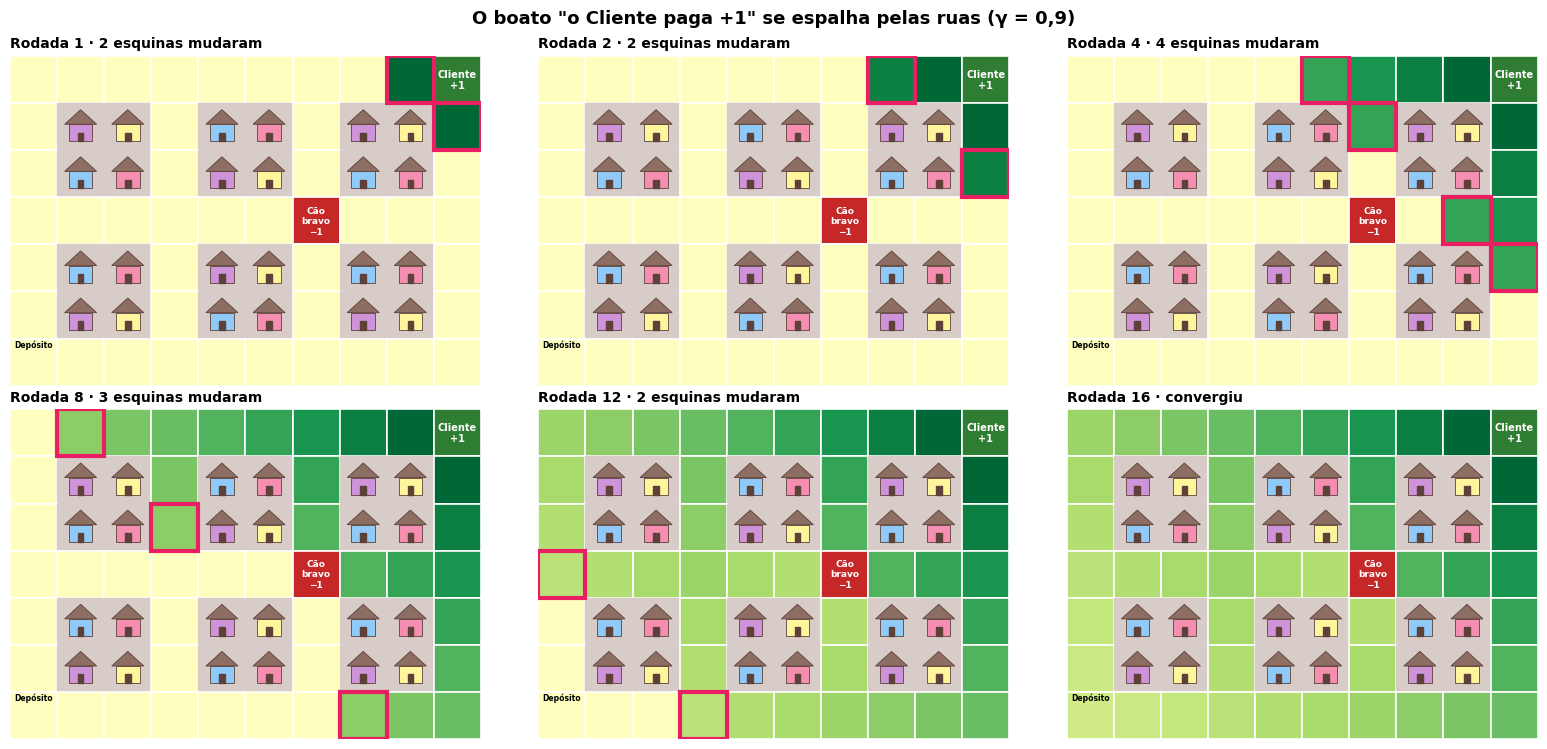

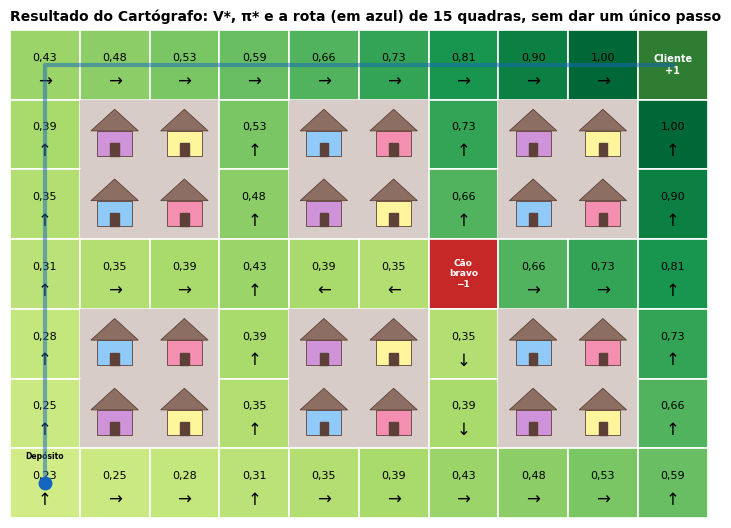

In [5]:
# O boato se espalhando pelo bairro (contorno rosa = esquinas que mudaram naquela rodada)
rodadas = [1, 2, 4, 8, 12, len(hist) - 1]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.6))
for ax, k in zip(axes.flat, rodadas):
    mudou = [s for s in ESTADOS if abs(hist[k][s] - hist[k - 1][s]) > 1e-9]
    desenhar_bairro(ax, hist[k], destaque=mudou, numeros=False,
                    titulo=f'Rodada {k}' + (' · convergiu' if k == len(hist) - 1 else f' · {len(mudou)} esquinas mudaram'))
fig.suptitle(f'O boato "o Cliente paga +1" se espalha pelas ruas (γ = {br(GAMMA, 1)})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 6.4))
rota = seguir(pi_vi, DEPOSITO)
desenhar_bairro(ax, V_vi, pi_vi, rota=rota,
                titulo=f'Resultado do Cartógrafo: V*, π* e a rota (em azul) de {len(rota) - 1} quadras, sem dar um único passo')
plt.show()

In [6]:
# @title ▶️ Animação do boato, rodada a rodada (rode e use os botões ◀ ▶)
fig, ax = plt.subplots(figsize=(8, 5.8), dpi=65)


def quadro(k):
    k = min(k, len(hist) - 1)
    ax.clear()
    mudou = [s for s in ESTADOS if k > 0 and abs(hist[k][s] - hist[k - 1][s]) > 1e-9]
    desenhar_bairro(ax, hist[k], destaque=mudou, titulo=f'Rodada {k}: {len(mudou)} esquinas mudaram')
    return []


anim = animation.FuncAnimation(fig, quadro, frames=len(hist) + 2, interval=700)
plt.close(fig)
HTML(anim.to_jshtml(default_mode='once'))

**🔎 O que observar**
- **Uma quadra por rodada:** na rodada 1 só as esquinas vizinhas ao Cliente sabem dele. A cada rodada, o contorno rosa avança uma quadra pelas ruas, contornando os quarteirões.
- **O valor cai 10% a cada quadra:** no zoom da rua de cima, 1 → 0,9 → 0,81 → 0,73 → 0,66, a mesma sequência do slide 79 e da grade 4×3 (slides 62–64).
- **O Depósito fica a 15 quadras:** a notícia chega lá na rodada 15, já bem "encolhida" (0,9¹⁴ ≈ 0,23).
- **O cão bravo não "contamina" o bairro:** como o Cartógrafo escolhe o **max**, ele simplesmente nunca entra na esquina do cão. Só as setas vizinhas apontam para longe dele.
- **Empates:** do Depósito existem várias rotas de 15 quadras (por cima, por baixo...). Todas valem o mesmo; o código escolhe a primeira na ordem ↑ → ↓ ←.

### 🤔 Pergunta do slide 79: e se γ = 0,5? Até onde o boato chegaria "forte"?

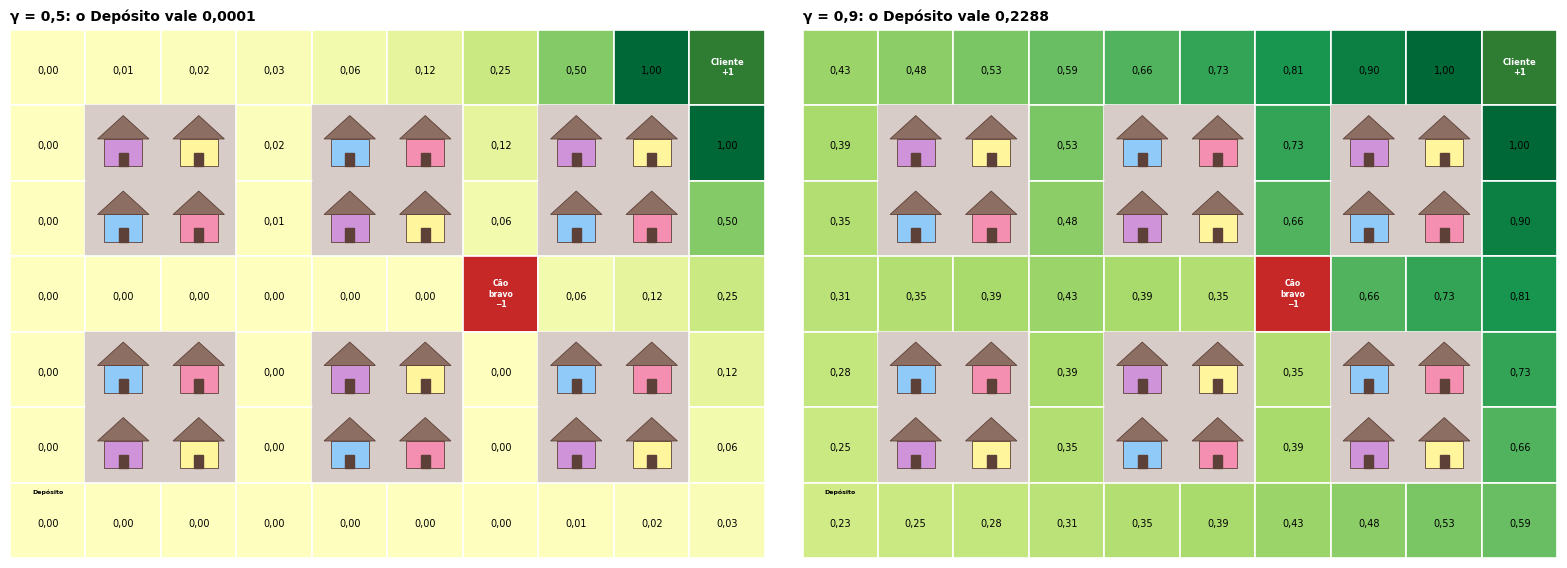

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
for ax, g in zip(axes, [0.5, 0.9]):
    V, pol, h = value_iteration(g)
    desenhar_bairro(ax, V, numeros=True, fonte=7,
                    titulo=f'γ = {br(g, 1)}: o Depósito vale {br(V[DEPOSITO], 4)}')
plt.tight_layout()
plt.show()

**🔎 Resposta:** com γ = 0,5, o boato perde **metade** a cada quadra. Três quadras depois do Cliente, ele já vale só 0,13, e no Depósito praticamente **zero**: um entregador imediatista nem "sente" o Cliente lá do outro lado do bairro. Com γ = 0,9, o Depósito ainda vale 0,23.

### 🎮 Desafio: obra na rua!

A prefeitura fechou um pedaço da rua de cima (um `#` novo) e o cão bravo mudou para a rua de baixo. Antes de rodar: **por onde o Cartógrafo vai mandar o entregador agora?**

Depois, invente o seu bairro: mude o `MAPA_DESAFIO` (feche ruas com `#`, mova o `X` ou o `C`) e rode de novo.

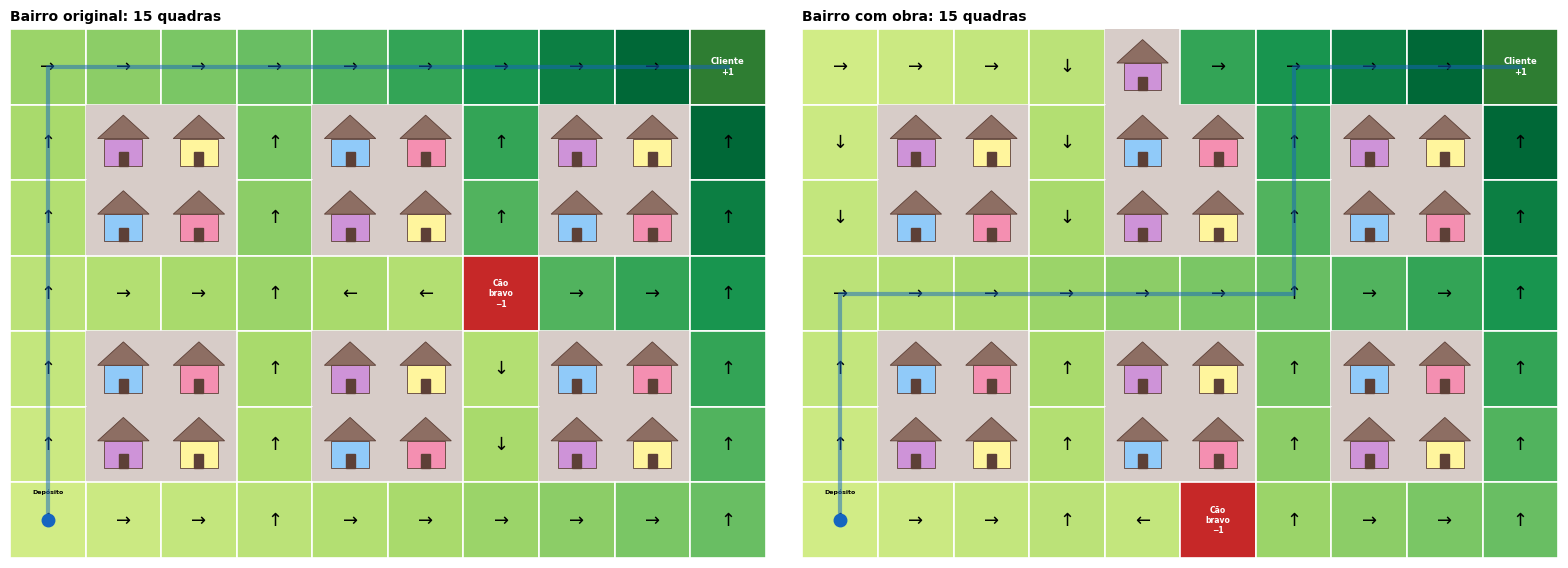

In [8]:
MAPA_DESAFIO = '''
. . . . # . . . . C
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
D . . . . X . . . .
'''   # 👈 edite à vontade: '.' rua, '#' quarteirão/obra, 'D' depósito, 'C' cliente, 'X' cão

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
for ax, (nome, texto) in zip(axes, [('Bairro original', MAPA), ('Bairro com obra', MAPA_DESAFIO)]):
    usar_mapa(texto)
    V, pol, h = value_iteration(GAMMA)
    rota = seguir(pol, DEPOSITO)
    chegou = GRADE[rota[-1][0]][rota[-1][1]] == 'C'
    desenhar_bairro(ax, V, pol, rota=rota, numeros=False, fonte=7,
                    titulo=f'{nome}: {len(rota) - 1} quadras' + ('' if chegou else ' (não chega ao Cliente!)'))
usar_mapa(MAPA)    # volta ao bairro original para as próximas seções
plt.tight_layout()
plt.show()

**🔎 O que observar:** com a rua de cima fechada e o cão na rua de baixo, o Cartógrafo **corta pela rua do meio**, sem dar um único passo de teste. Ele só consegue isso porque **tem o mapa**: sabe onde estão a obra e o cão antes de sair.

> **Custo (slide 78):** cada rodada percorre **todas** as esquinas e ações. Aqui são 44 esquinas × 4 ações. Num jogo com bilhões de estados, o Cartógrafo nunca terminaria o mapa.

---
## 2. 🔧 O Treinador — Policy Iteration (slide 80)

O Treinador também tem o mapa, mas trabalha de outro jeito. Ele começa com **uma estratégia qualquer** e repete o ciclo:

1. **Avaliar:** com a política **fixa**, calcula quanto vale cada esquina ($V^\pi$). Não há max: o entregador só segue a regra.
2. **Melhorar:** em cada esquina, troca pela ação de maior valor (argmax).
3. **Parou de mudar?** A política é ótima.

**A história:** o chefe chegou com uma regra pronta, sem olhar o mapa: **"vá sempre para a direita (→); na última rua, suba (↑)"**.

> 🤔 **Palpite:** onde a regra do chefe dá errado? Quantas rodadas o Treinador leva para consertá-la?

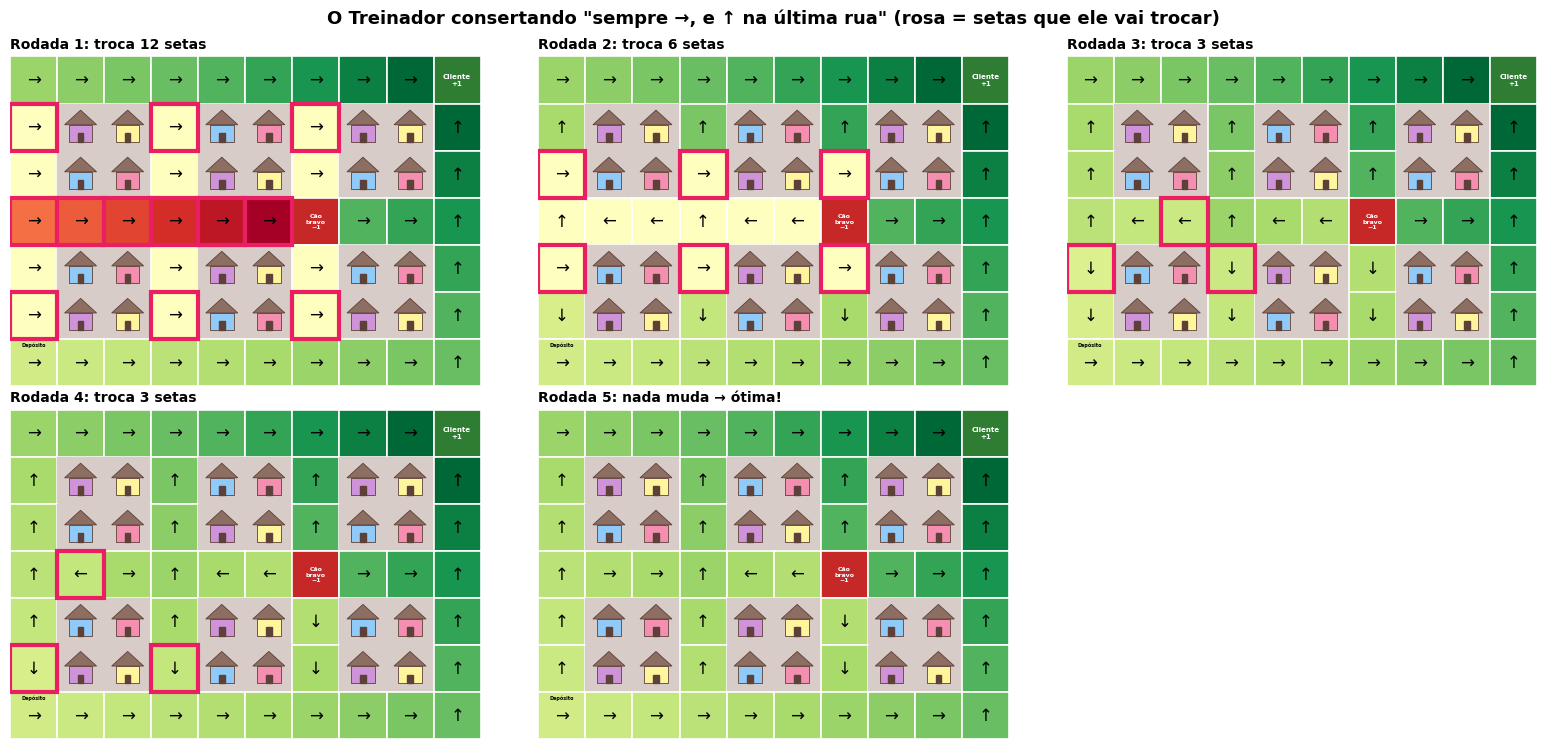

Rodada    varreduras da avaliação  setas trocadas  V(Depósito)
1                              16              12         0,23
2                              17               6         0,23
3                              18               3         0,23
4                              17               3         0,23
5                              16               0         0,23

"sempre →, e ↑ na última rua": 5 rodadas até a política ótima.


In [9]:
def avaliar(politica, gamma=0.9, theta=1e-6):
    '''1 · AVALIAR: V da política fixa (sem max). Devolve (V, número de varreduras).
    A política pode dar uma ação ('→') ou chances ({'↑': .5, '→': .5}) para cada esquina.'''
    V, varreduras = tabela_vazia(), 0
    while True:
        novo = V.copy()
        for s in ESTADOS:
            escolha = politica[s]
            chances = {escolha: 1.0} if isinstance(escolha, str) else escolha
            novo[s] = sum(p * valor_acao(V, s, a, gamma) for a, p in chances.items())
        varreduras += 1
        if np.nanmax(np.abs(novo - V)) < theta:
            return novo, varreduras
        V = novo


def melhorar(V, politica, gamma=0.9):
    '''2 · MELHORAR: em cada esquina, troca pela melhor ação (só troca se for estritamente melhor).'''
    nova = dict(politica)
    for s in ESTADOS:
        melhor = max(ACOES, key=lambda a: valor_acao(V, s, a, gamma))
        if valor_acao(V, s, melhor, gamma) > valor_acao(V, s, politica[s], gamma) + 1e-9:
            nova[s] = melhor
    return nova


def policy_iteration(regra, gamma=0.9):
    '''Repete avaliar → melhorar até a política parar de mudar. "regra" diz a seta de cada esquina.'''
    politica = {s: regra(s) for s in ESTADOS}
    rodadas = []
    while True:
        V, varreduras = avaliar(politica, gamma)
        nova = melhorar(V, politica, gamma)
        mudou = [s for s in ESTADOS if nova[s] != politica[s]]
        rodadas.append((politica, V, varreduras, mudou))
        if not mudou:
            return rodadas
        politica = nova


def mostrar_treinador(regra, nome):
    rodadas = policy_iteration(regra)
    n = len(rodadas)
    escolhidas = list(range(n)) if n <= 6 else [0, 1, 2, n // 2, n - 2, n - 1]
    fig, axes = plt.subplots(2, 3, figsize=(16, 7.6))
    for ax in axes.flat:
        ax.axis('off')
    for ax, k in zip(axes.flat, escolhidas):
        pol, V, varr, mudou = rodadas[k]
        desenhar_bairro(ax, V, pol, destaque=mudou, numeros=False, fonte=6,
                        titulo=f'Rodada {k + 1}: ' + (f'troca {len(mudou)} setas' if mudou else 'nada muda → ótima!'))
    fig.suptitle(f'O Treinador consertando "{nome}" (rosa = setas que ele vai trocar)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
    print(f"{'Rodada':<8}{'varreduras da avaliação':>25}{'setas trocadas':>16}{'V(Depósito)':>13}")
    for k, (pol, V, varr, mudou) in enumerate(rodadas):
        print(f'{k + 1:<8}{varr:>25}{len(mudou):>16}{br(V[DEPOSITO]):>13}')
    print(f'\n"{nome}": {n} rodadas até a política ótima.')


regra_do_chefe = lambda s: '↑' if s[1] == COL - 1 else '→'   # 👈 a regra do chefe
mostrar_treinador(regra_do_chefe, 'sempre →, e ↑ na última rua')

**🔎 O que observar**
- **Rodada 1, avaliar:** a regra do chefe tem dois defeitos que só aparecem no mapa colorido:
  - na **rua do meio**, "sempre →" leva o entregador **direto ao cão bravo** (esquinas vermelhas);
  - nas **ruas verticais**, "→" bate no quarteirão e o entregador fica **parado para sempre** (valor 0).
- **Rodada 1, melhorar:** o Treinador troca **só os pontos fracos** (contorno rosa). As esquinas que já levavam ao Cliente ficam como estavam.
- **Rodadas seguintes:** cada conserto faz o valor bom "escorrer" para as esquinas vizinhas, que então também são consertadas. Repare que cada rodada é "cara": a avaliação tem várias varreduras dentro.

### 🎮 Desafio: invente a pior regra possível

Troque a regra abaixo e veja quantas rodadas o Treinador precisa. Tente `lambda s: '←'` (o entregador que sempre volta) ou `lambda s: '↓'`.

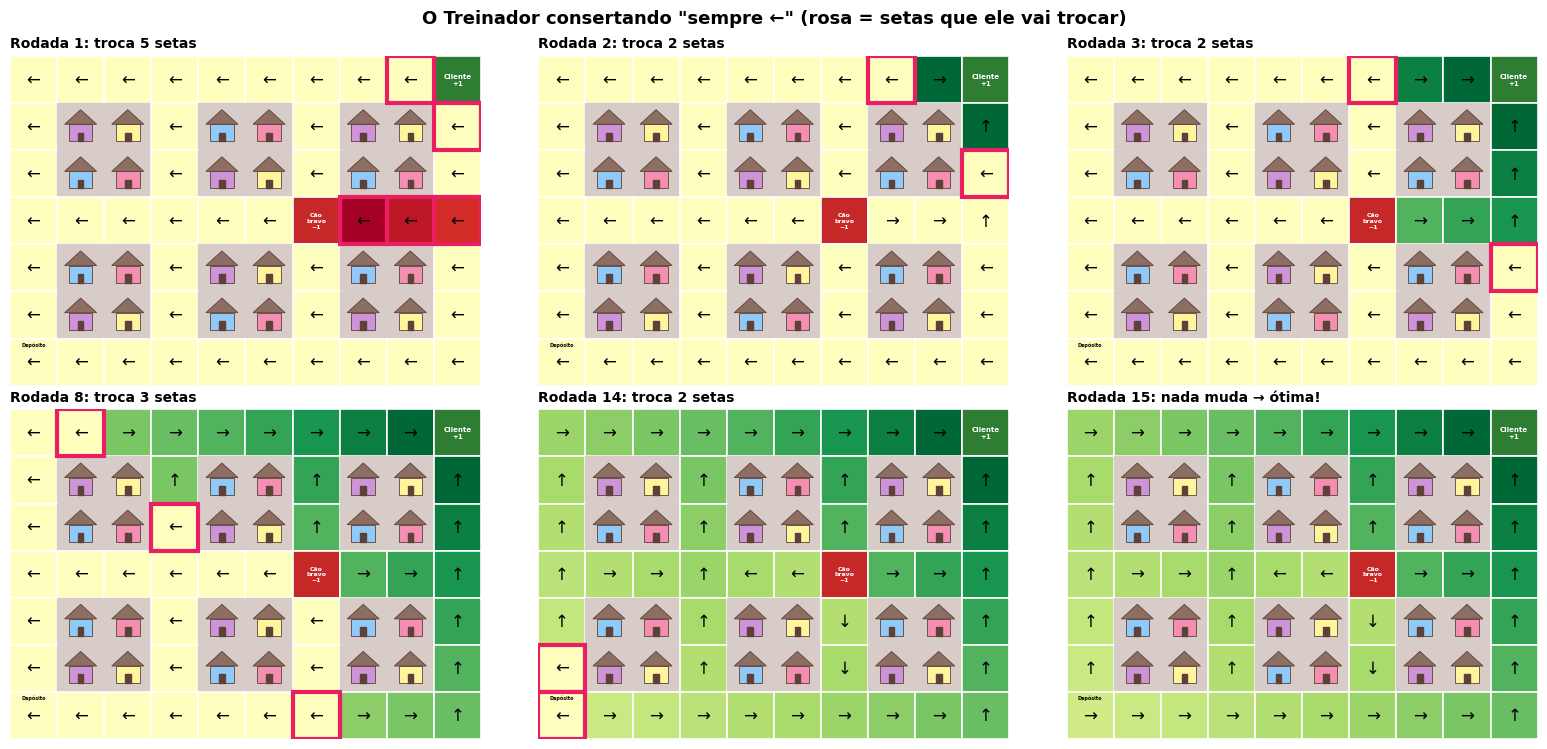

Rodada    varreduras da avaliação  setas trocadas  V(Depósito)
1                               4               5         0,00
2                               2               2         0,00
3                               6               2         0,00
4                               6               3         0,00
5                               6               3         0,00
6                               7               2         0,00
7                               8               3         0,00
8                               9               3         0,00
9                              10               4         0,00
10                             12               5         0,00
11                             12               4         0,00
12                             13               2         0,00
13                             14               2         0,00
14                             15               2         0,00
15                             16               0      

In [10]:
mostrar_treinador(lambda s: '←', 'sempre ←')   # 👈 troque à vontade

**🔎 Cartógrafo × Treinador (slide 80)**

| | 🗺️ Value Iteration | 🔧 Policy Iteration |
|---|---|---|
| Cada rodada | 1 varredura barata (com max) | avaliação completa (muitas varreduras) + 1 melhoria |
| Nº de rodadas | muitas | poucas, se o palpite inicial for bom |
| O que estabiliza primeiro | os valores | **a política** |

Com a regra do chefe, que já acertava boa parte do bairro, o Treinador precisa de poucas rodadas. Com "sempre ←", que erra tudo, ele precisa de muitas: **um bom palpite inicial economiza trabalho**.

**O limite dos dois:** ambos precisam do **mapa** (a função `passo`, ou seja, P e R). E se o entregador não tiver mapa nenhum? → Monte Carlo e TD.

---
## 3. 🍽️ O Crítico — Monte Carlo (slide 81)

**Mudança de cenário:** agora o entregador **perdeu o mapa** e a bicicleta está desgovernada. Em cada esquina, ela entra **numa rua aberta qualquer, ao acaso**. Cada pedido começa numa esquina sorteada do bairro.

A pergunta passa a ser: **partindo de cada esquina, quanto o entregador ganha, em média?** Perto do Cliente, a gorjeta. Perto do cão, a mordida. Longe de tudo, quase nada, porque a gorjeta encolhe 10% por quadra.

O **Crítico** é como quem avalia um restaurante: só dá a nota **depois de comer a refeição inteira**.

1. Jogue a entrega **até o fim** (Cliente ou cão).
2. Calcule o retorno **G** de cada esquina visitada, de trás para frente: $G = R + \gamma \cdot G_{\text{seguinte}}$.
3. **V(s) = média** das notas que s já recebeu.

> Esses agentes só **avaliam** a política da bicicleta desgovernada. Aprender a **escolher** a ação sem mapa é o próximo passo: o Q-Learning.

🚲 Entrega de 12 quadras, de (4, 3) até o Cliente 🏁 (+1)

🍽️ O Crítico espera o fim e anota, de trás para frente (G = R + 0,9·G seguinte):
   esquina (4, 3): nota 0,31
   esquina (3, 3): nota 0,35
   esquina (2, 3): nota 0,39
   esquina (1, 3): nota 0,43
   esquina (2, 3): nota 0,48
   esquina (1, 3): nota 0,53
   esquina (0, 3): nota 0,59
   esquina (0, 4): nota 0,66
   esquina (0, 5): nota 0,73
   esquina (0, 6): nota 0,81
   esquina (0, 7): nota 0,90
   esquina (0, 8): nota 1,00


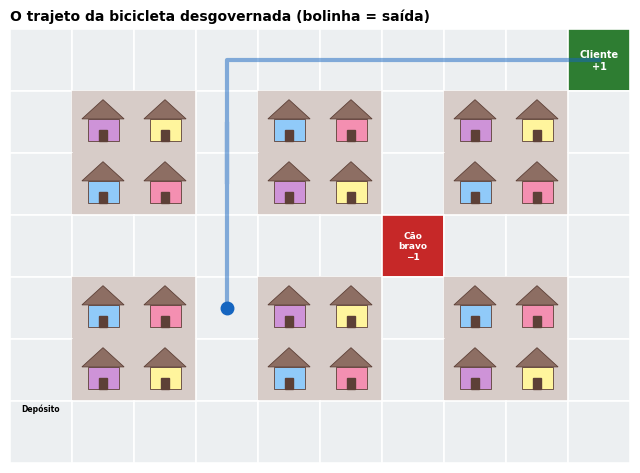

In [11]:
def ruas_abertas(s):
    '''As direções em que a bicicleta consegue andar (sem bater em quarteirão).'''
    return [a for a in ACOES if passo(s, a)[0] != s]


def entrega(rng, inicio=None):
    '''Uma entrega da bicicleta desgovernada até o fim. Devolve [(esquina, recompensa), ...].'''
    s = inicio if inicio else ESTADOS[rng.integers(len(ESTADOS))]
    passos = []
    while True:
        abertas = ruas_abertas(s)
        s2, r, fim = passo(s, abertas[rng.integers(len(abertas))])
        passos.append((s, r))
        s = s2
        if fim:
            return passos


rng = np.random.default_rng(334)
passos = entrega(rng)
fim = 'Cliente 🏁 (+1)' if passos[-1][1] > 0 else 'Cão bravo 🐕 (−1)'
print(f'🚲 Entrega de {len(passos)} quadras, de {passos[0][0]} até o {fim}\n')

print('🍽️ O Crítico espera o fim e anota, de trás para frente (G = R + 0,9·G seguinte):')
G, notas = 0.0, []
for s, r in reversed(passos):
    G = r + 0.9 * G
    notas.append((s, G))
for s, G in reversed(notas):
    print(f'   esquina {s}: nota {br(G)}')

ultima, r_final = passos[-1]
destino = next(passo(ultima, a)[0] for a in ACOES if passo(ultima, a)[1:] == (r_final, True))
fig, ax = plt.subplots(figsize=(8, 5.8))
desenhar_bairro(ax, rota=[s for s, _ in passos] + [destino],
                titulo='O trajeto da bicicleta desgovernada (bolinha = saída)')
plt.show()

> 🤔 **Palpite:** depois de **só essa** entrega, o Crítico acha que a esquina de saída vale a nota que ela recebeu. Ele está certo? E as esquinas por onde a bicicleta **não** passou?

O gabarito existe, mas quem consegue calculá-lo é quem **tem o mapa**. Vamos pedir ao Treinador (`avaliar`) que calcule o valor verdadeiro, só para comparar. O Crítico **não vê** este gabarito.

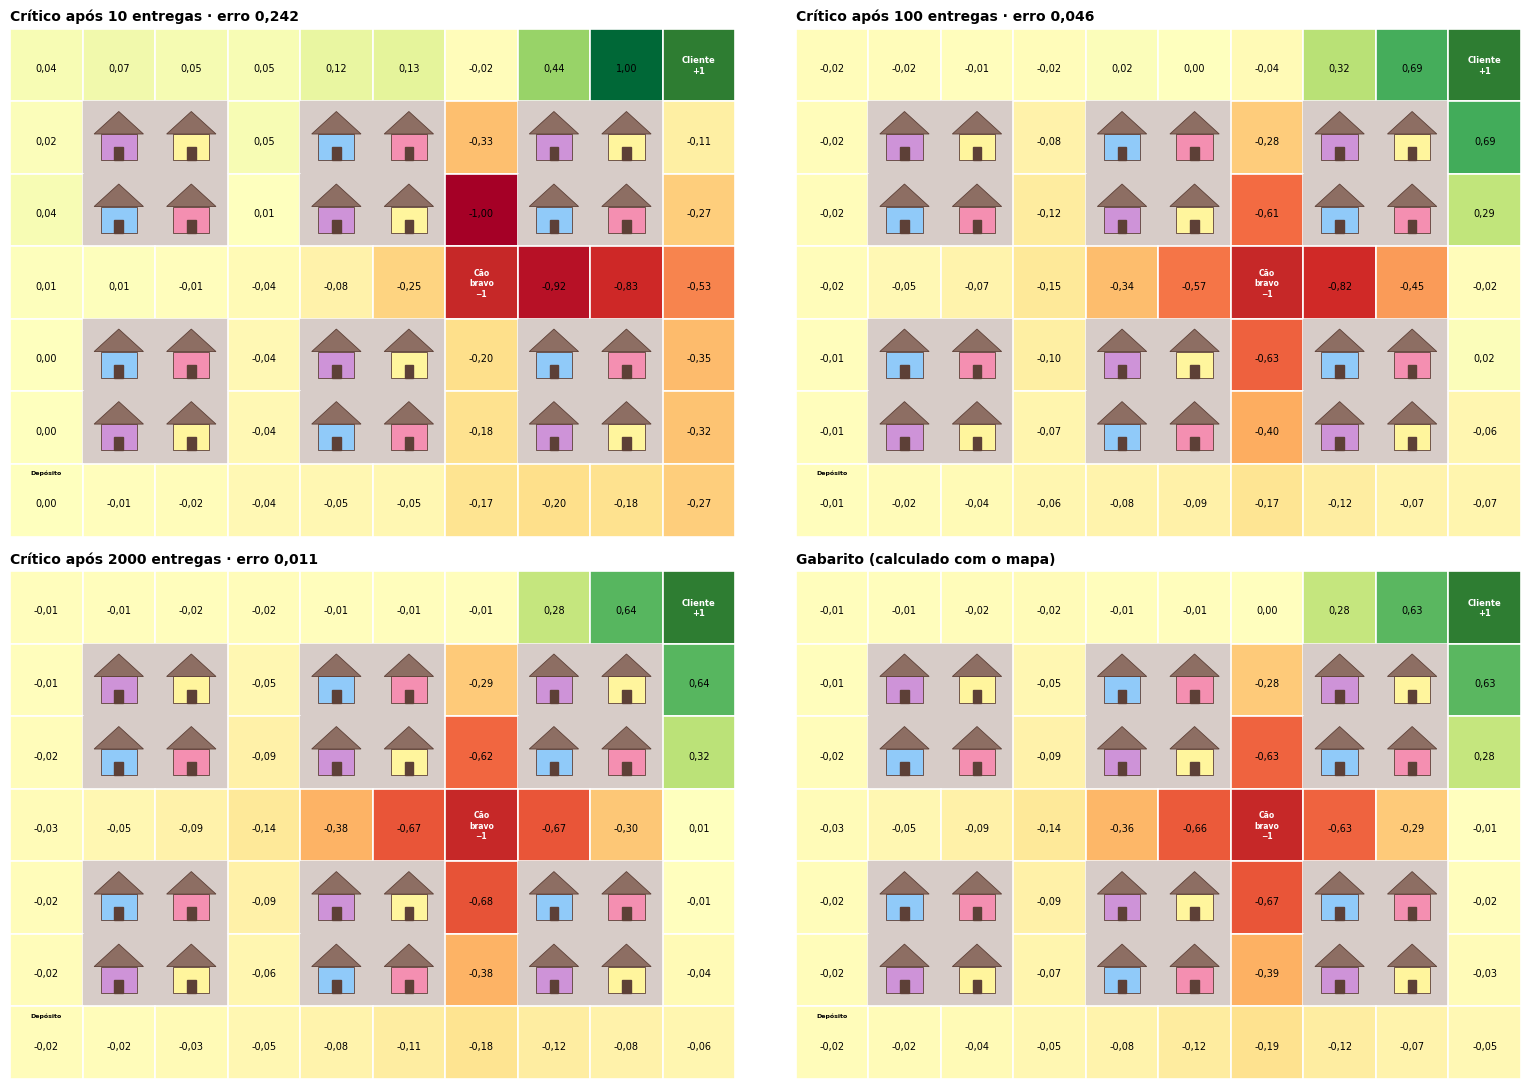

In [12]:
POLITICA_DESGOVERNADA = {s: {a: 1 / len(ruas_abertas(s)) for a in ruas_abertas(s)} for s in ESTADOS}
V_REAL, _ = avaliar(POLITICA_DESGOVERNADA, gamma=0.9, theta=1e-10)   # o gabarito (só para comparar)
RUAS = ~np.isnan(V_REAL)
erro_medio = lambda V: np.sqrt(np.mean((V[RUAS] - V_REAL[RUAS]) ** 2))


def critico(n_entregas, seed=1, fotos=()):
    '''Monte Carlo pela média: soma das notas ÷ número de notas, em cada esquina.'''
    rng = np.random.default_rng(seed)
    soma, contagem = tabela_vazia(), tabela_vazia()
    guardadas = {}
    for n in range(1, n_entregas + 1):
        G = 0.0
        for s, r in reversed(entrega(rng)):
            G = r + 0.9 * G
            soma[s] += G
            contagem[s] += 1
        if n in fotos:
            guardadas[n] = (np.where(contagem > 0, soma / np.maximum(contagem, 1), 0), contagem.copy())
    return guardadas


fotos = critico(2000, fotos=(10, 100, 2000))
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, n in zip(axes.flat, [10, 100, 2000]):
    V, cont = fotos[n]
    nunca = [s for s in ESTADOS if cont[s] == 0]
    desenhar_bairro(ax, V, destaque=nunca, fonte=7,
                    titulo=f'Crítico após {n} entregas · erro {br(erro_medio(V), 3)}'
                           + (f' · {len(nunca)} esquinas nunca visitadas (rosa)' if nunca else ''))
desenhar_bairro(axes[1, 1], V_REAL, fonte=7, titulo='Gabarito (calculado com o mapa)')
plt.tight_layout()
plt.show()

**🔎 O que observar**
- **Começo maluco:** com 10 entregas, várias esquinas recebem só uma ou duas notas, e o mapa fica "manchado". É a **variância alta** do slide 81: uma entrega atípica distorce a média.
- **Com 2.000 entregas,** o mapa do Crítico fica parecido com o gabarito: verde em volta do Cliente, vermelho em volta do cão e quase 0 longe dos dois. É a Lei dos Grandes Números, a mesma do clima de longo prazo no notebook de Markov.
- **Sem mapa nenhum:** o Crítico nunca usou a função `passo` para planejar. Aprendeu só andando.
- **O limite:** ele **precisa que a entrega acabe** para dar a nota. Numa tarefa sem fim, ele nunca aprenderia nada.

> **Truque que usaremos na seção 5:** a média pode ser atualizada sem guardar todas as notas, com $V \leftarrow V + \frac{1}{n}(G - V)$. Trocando $\frac{1}{n}$ por um α fixo, chega-se ao Monte Carlo "com α", que vai correr contra o TD.

---
## 4. 🚗 O Motorista — Diferença Temporal (slides 83 e 84) · item 1 do slide 85

O Motorista **não espera chegar**. Ele corrige a previsão **a cada esquina**, usando a própria previsão seguinte como alvo:

$$V(s) \leftarrow V(s) + \alpha\,\big[\,\underbrace{R + \gamma\,V(s')}_{\text{o que acabei de ver}} - \underbrace{V(s)}_{\text{o que eu achava}}\,\big]$$

A diferença entre os dois é o **erro TD**, a "surpresa". α diz quanto dessa surpresa eu aceito de cada vez.

### A conta do slide 84: fim do expediente, a volta para casa

Depois das entregas, o entregador volta de carro do trabalho para casa. Aqui a "recompensa" é o **tempo gasto**, com γ = 1 e α = 0,5.

| | |
|---|---|
| 🏢 Saí do trabalho | palpite: V(trabalho) = **40 min** |
| 🚦 Trânsito na 1ª esquina! | já gastei **R = 15 min**; daqui faltam **V(s′) = 35 min** |

In [13]:
def atualizacao_td(V_s, R, V_prox, alfa, gamma=1.0):
    '''Uma atualização TD(0). Devolve (novo valor, erro TD).'''
    erro_td = R + gamma * V_prox - V_s
    return V_s + alfa * erro_td, erro_td


novo, erro = atualizacao_td(V_s=40, R=15, V_prox=35, alfa=0.5)
print('😲 A surpresa:  R + V(s\') = 15 + 35 = 50   →   erro TD = 50 − 40 =', f'{erro:+.0f}')
print(f'✏️ Corrijo já:  V = 40 + 0,5 × {erro:.0f} = {br(novo, 0)} min')

😲 A surpresa:  R + V(s') = 15 + 35 = 50   →   erro TD = 50 − 40 = +10
✏️ Corrijo já:  V = 40 + 0,5 × 10 = 45 min


> 🤔 **Desafio relâmpago (slide 84):** com α = 0,1, qual seria o novo V(trabalho)? E com α = 1? Calculem antes de rodar.

In [14]:
for alfa in [0.1, 0.5, 1.0]:
    novo, _ = atualizacao_td(40, 15, 35, alfa)
    print(f'α = {br(alfa, 1)}  →  V(trabalho) = {br(novo, 1)} min')
print('\nα = 1 joga fora o palpite antigo e confia 100% na novidade; α = 0,1 desconfia e anda só um pouquinho.')

α = 0,1  →  V(trabalho) = 41,0 min
α = 0,5  →  V(trabalho) = 45,0 min
α = 1,0  →  V(trabalho) = 50,0 min

α = 1 joga fora o palpite antigo e confia 100% na novidade; α = 0,1 desconfia e anda só um pouquinho.


### A viagem inteira: Monte Carlo × TD

A viagem continua. Em cada ponto, o motorista olha o relógio e refaz a previsão do **total**: o tempo decorrido + quanto ainda falta.

| Ponto da viagem | Decorrido | Previsão de quanto falta | Previsão do total |
|---|---|---|---|
| 🏢 Saindo do trabalho | 0 | 40 | 40 |
| 🚦 1ª esquina: trânsito! | 15 | 35 | 50 |
| 🛣️ Entrou na marginal, fluindo | 25 | 15 | 40 |
| 💥 Acidente na saída da marginal | 35 | 15 | 50 |
| 🏘️ Rua de casa | 51 | 4 | 55 |
| 🏠 **Chegou** | **55** | 0 | **55** |

- **🍽️ Monte Carlo** espera chegar (55 min) e só então corrige **todas** as previsões rumo ao real.
- **🚗 TD** corrige cada previsão **já no ponto seguinte**, rumo à próxima previsão.

> 🤔 **Palpite (slide 85):** na **1ª esquina**, para que lado cada um puxa a previsão: para cima ou para baixo?

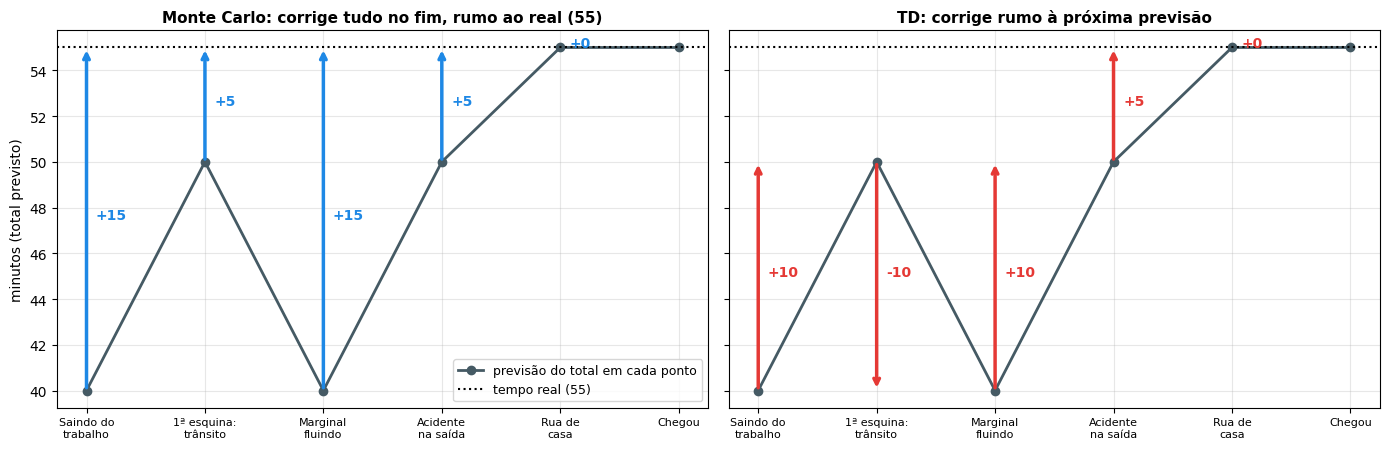

Correção sugerida em cada ponto (alvo − previsão):
ponto                         Monte Carlo     TD
Saindo do trabalho                    +15    +10
1ª esquina: trânsito                   +5    -10
Marginal fluindo                      +15    +10
Acidente na saída                      +5     +5
Rua de casa                            +0     +0


In [15]:
pontos = ['Saindo do\ntrabalho', '1ª esquina:\ntrânsito', 'Marginal\nfluindo', 'Acidente\nna saída', 'Rua de\ncasa', 'Chegou']
previsao_total = np.array([40, 50, 40, 50, 55, 55])   # decorrido + previsão de quanto falta
real = 55

alvo_mc = np.full(5, real)            # MC: o resultado final, para todos
alvo_td = previsao_total[1:]          # TD: a previsão do ponto seguinte

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, alvo, titulo, cor in [(axes[0], alvo_mc, 'Monte Carlo: corrige tudo no fim, rumo ao real (55)', '#1E88E5'),
                              (axes[1], alvo_td, 'TD: corrige rumo à próxima previsão', '#E53935')]:
    ax.plot(range(6), previsao_total, 'o-', color='#455A64', lw=2, label='previsão do total em cada ponto')
    ax.axhline(real, color='k', ls=':', label='tempo real (55)')
    for i in range(5):
        ax.annotate('', xy=(i, alvo[i]), xytext=(i, previsao_total[i]),
                    arrowprops=dict(arrowstyle='->', color=cor, lw=2.5))
        ax.text(i + .08, (alvo[i] + previsao_total[i]) / 2, f'{alvo[i] - previsao_total[i]:+d}', color=cor, fontweight='bold')
    ax.set_xticks(range(6), pontos, fontsize=8)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.grid(alpha=.3)
axes[0].set_ylabel('minutos (total previsto)')
axes[0].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print("Correção sugerida em cada ponto (alvo − previsão):")
print(f"{'ponto':28s} {'Monte Carlo':>12s} {'TD':>6s}")
for i in range(5):
    print(f"{pontos[i].replace(chr(10), ' '):28s} {alvo_mc[i] - previsao_total[i]:+12d} {alvo_td[i] - previsao_total[i]:+6d}")

**🔎 O que observar**
- **"Saindo do trabalho":** o TD corrige **+10 já na 1ª esquina**, a conta do slide 84, sem saber como a viagem termina. O MC só corrige (+15) depois de chegar em casa.
- **"1ª esquina": os dois discordam.** O TD puxa para **baixo** (−10), porque no ponto seguinte a marginal estava fluindo. O MC puxa para **cima** (+5), porque já sabe que a viagem acabou em 55. O TD reage ao que vê agora; o MC, ao resultado final.
- O TD aprende com a **própria próxima estimativa**, e isso se chama *bootstrapping* (slide 82).

---
## 5. Crítico × Motorista no bairro (slide 82) · item 2 do slide 85

De volta à bicicleta desgovernada da seção 3. Agora os dois aprendem **lado a lado**, com as **mesmas entregas** (mesma sorte) e α = 0,1. Os dois começam achando que toda esquina vale 0.

> 🤔 **Palpite:** numa entrega que termina no **cão bravo**, quantas esquinas cada um altera? Qual dos dois mapas "pisca" mais?

In [16]:
def monte_carlo(V, passos, alfa, gamma=0.9):
    '''🍽️ Espera o fim: cada esquina visitada anda rumo ao retorno REAL G (calculado de trás para frente).'''
    G = 0.0
    for s, r in reversed(passos):
        G = r + gamma * G
        V[s] += alfa * (G - V[s])


def td0(V, passos, alfa, gamma=0.9):
    '''🚗 A cada passo: o alvo é a recompensa + o valor estimado da próxima esquina.'''
    for k, (s, r) in enumerate(passos):
        v_prox = V[passos[k + 1][0]] if k + 1 < len(passos) else 0.0   # fim: não há futuro
        V[s] += alfa * (r + gamma * v_prox - V[s])

In [17]:
# @title ▶️ Animação: os dois aprendendo (rode e use os botões ◀ ▶)
rng = np.random.default_rng(0)
V_mc, V_td = tabela_vazia(), tabela_vazia()
quadros = [(0, V_mc.copy(), V_td.copy(), '')]
for n in range(1, 201):
    passos = entrega(rng)
    monte_carlo(V_mc, passos, .1)
    td0(V_td, passos, .1)
    if n <= 10 or n % 10 == 0:
        fim = 'Cliente (+1)' if passos[-1][1] > 0 else 'cão bravo (−1)'
        quadros.append((n, V_mc.copy(), V_td.copy(), f'{len(passos)} quadras, terminou no {fim}'))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), dpi=60)
fig.subplots_adjust(top=.8, bottom=.02, left=.01, right=.99, wspace=.04)


def quadro(k):
    n, vm, vt, info = quadros[min(k, len(quadros) - 1)]
    for ax in axes:
        ax.clear()
    desenhar_bairro(axes[0], vm, numeros=False, titulo=f'Monte Carlo (Crítico) · erro {br(erro_medio(vm), 3)}')
    desenhar_bairro(axes[1], vt, numeros=False, titulo=f'TD (Motorista) · erro {br(erro_medio(vt), 3)}')
    desenhar_bairro(axes[2], V_REAL, numeros=False, titulo='Gabarito (calculado com o mapa)')
    fig.suptitle(f'Depois de {n} entrega(s)' + (f'  ·  última: {info}' if info else ''), fontsize=13)
    return []


anim = animation.FuncAnimation(fig, quadro, frames=len(quadros) + 3, interval=700)
plt.close(fig)
HTML(anim.to_jshtml(default_mode='once'))

**🔎 O que observar** (use ◀ ▶ nas primeiras 10 entregas)
- **Entrega que termina no cão:** o Monte Carlo pinta de vermelho **todo o trajeto** de uma vez, porque todas as esquinas visitadas recebem a nota da mordida. O TD só mexe de verdade na última esquina, que viu o cão de perto.
- **O TD espalha a informação de vizinho para vizinho,** como o boato do Cartógrafo, só que aprendendo andando, sem mapa. É também o valor que "vaza para trás" na cobrinha (slide 104).
- **O Monte Carlo pisca mais:** cada entrega pinta trajetos inteiros. Isso é a **variância alta** do slide 82. O TD muda devagar, mas depende das próprias estimativas, que no começo estão erradas (o "algum viés").

---
## 6. 🏁 A corrida: quem erra menos? · item 3 do slide 85

São 30 corridas de 200 entregas para cada método e para três valores de α. A medida é o **erro médio** entre o mapa estimado e o gabarito: quanto menor, melhor. (Esta célula leva uns 15 segundos.)

> 🤔 **Palpite:** quem termina com menos erro, o Crítico ou o Motorista? α grande ajuda ou atrapalha?

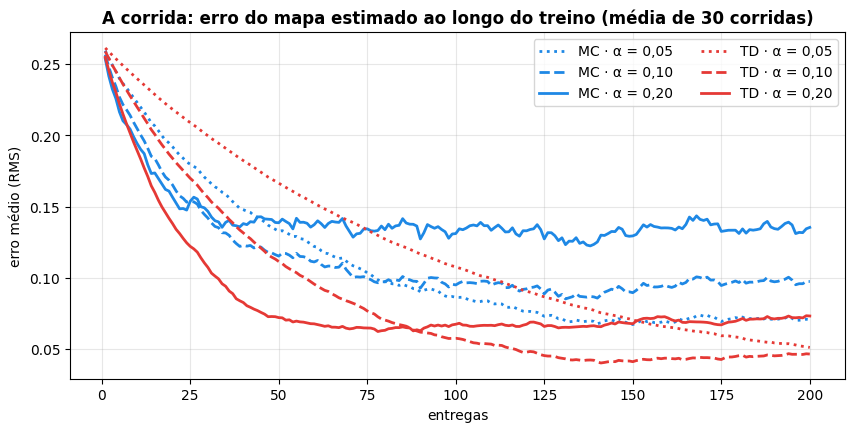

método     α  erro após 20 entregas  erro após 200
MC      0,05                  0,192          0,071
MC      0,10                  0,165          0,097
MC      0,20                  0,157          0,135
TD      0,05                  0,218          0,051
TD      0,10                  0,184          0,046
TD      0,20                  0,138          0,073

🏆 Menor erro final: TD com α = 0,10


In [18]:
def curva_de_erro(metodo, alfa, n_corridas=30, n_entregas=200):
    erros = np.zeros(n_entregas)
    for corrida in range(n_corridas):
        rng = np.random.default_rng(corrida)
        V = tabela_vazia()
        for n in range(n_entregas):
            metodo(V, entrega(rng), alfa)
            erros[n] += erro_medio(V)
    return erros / n_corridas


fig, ax = plt.subplots(figsize=(10, 4.5))
resumo = []
for metodo, nome, cor in [(monte_carlo, 'MC', '#1E88E5'), (td0, 'TD', '#E53935')]:
    for alfa, estilo in [(.05, ':'), (.1, '--'), (.2, '-')]:
        erro = curva_de_erro(metodo, alfa)
        ax.plot(range(1, len(erro) + 1), erro, estilo, color=cor, lw=2, label=f'{nome} · α = {br(alfa)}')
        resumo.append((nome, alfa, erro[19], erro[-1]))
ax.set_xlabel('entregas'); ax.set_ylabel('erro médio (RMS)')
ax.set_title('A corrida: erro do mapa estimado ao longo do treino (média de 30 corridas)', fontweight='bold')
ax.grid(alpha=.3); ax.legend(ncol=2)
plt.show()

print(f"{'método':6s} {'α':>5s} {'erro após 20 entregas':>22s} {'erro após 200':>14s}")
for nome, alfa, e20, e200 in resumo:
    print(f"{nome:6s} {br(alfa):>5s} {br(e20, 3):>22s} {br(e200, 3):>14s}")
vencedor = min(resumo, key=lambda x: x[3])
print(f'\n🏆 Menor erro final: {vencedor[0]} com α = {br(vencedor[1])}')

**🔎 O que observar**
- **Largada × chegada:** nas primeiras entregas, o Monte Carlo às vezes larga na frente, porque o TD ainda está espalhando a notícia de vizinho para vizinho. Mas, depois de 200 entregas, **o TD termina com menos erro para os três valores de α**. É o resultado clássico de Sutton & Barto (exemplo 6.2), agora num bairro inteiro.
- **α grande** aprende rápido no começo, mas o mapa fica "tremendo" e o erro para de cair. **α pequeno** é estável, porém lento. É o mesmo dilema do "Mexa no α" do Q-Learning (slide 106).
- **A vantagem que não aparece aqui:** o TD **não precisa que a entrega termine**. Um robô de armazém que trabalha sem parar nunca "chega ao fim", e só o TD consegue aprender nele.

---
## 🏆 Placar final: os quatro entregadores

| | Personagem | Precisa do mapa? | Quando corrige | O que vimos no bairro |
|---|---|---|---|---|
| 🗺️ | Cartógrafo (Value Iteration) | sim | antes de andar, rodada a rodada | o boato chega ao Depósito na rodada 15; desvia da obra sem testar |
| 🔧 | Treinador (Policy Iteration) | sim | avalia a regra inteira, depois melhora | conserta a regra do chefe em poucas rodadas |
| 🍽️ | Crítico (Monte Carlo) | **não** | no **fim** da entrega | sem viés, mas o mapa "pisca" muito no começo |
| 🚗 | Motorista (TD) | **não** | a **cada passo** | espalha o valor de vizinho para vizinho |

**Todos buscam o mesmo prêmio (slide 77):** V\* e π\*. Muda só o caminho até lá.

## 💭 Para pensar (em dupla)

1. **Mapa ou não?** Num app de entregas de verdade, o que seria "ter o mapa" (P e R)? Dá para saber de antemão onde estão as obras e os cães, ou o agente precisa aprender andando?
2. **Slide 82:** "MC: sem viés, mas variância alta". Onde você **viu** a variância alta: nos mapas do Crítico (seção 3) ou na animação (seção 5)?
3. **Bootstrapping:** o TD usa a **própria estimativa** como alvo. Se ela estiver errada, o alvo também está. Por que, mesmo assim, ele funciona?
4. **Esquinas esquecidas:** no mapa do Crítico com poucas entregas, algumas esquinas quase não foram visitadas. O que isso diz sobre a importância de **explorar** (o ε-greedy que vem a seguir)?
5. **Ponte com o Q-Learning:** compare a regra do TD, $V(s) \leftarrow V(s) + \alpha[R + \gamma V(s') - V(s)]$, com a do Q-Learning (slide 96). O que mudou?
6. **Negócio (slide 82):** para ajustar ofertas a clientes que **nunca "terminam"** o relacionamento, qual dos dois serve: o Crítico ou o Motorista? Por quê?